In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

np.random.seed(42)

In [5]:
uploaded = files.upload()          # select metr-la.csv
CSV_PATH = "metr-la.csv"

Saving metr-la.csv to metr-la.csv


In [6]:
df = pd.read_csv(CSV_PATH)
first = df.columns[0]

if df[first].dtype == object:                       # first column holds timestamps (strings)
    df.index = pd.to_datetime(df[first])
    df = df.drop(columns=first)
else:
    if str(first).lower().startswith(("unnamed", "index")):   # stray integer index column
        df = df.drop(columns=first)
    print("No timestamp column found -> building one (5-min steps from 2012-03-01)")
    df.index = pd.date_range("2012-03-01", periods=len(df), freq="5min")

df.index.name = "timestamp"
df = df.apply(pd.to_numeric, errors="coerce").astype("float32")

print("Shape (time steps, sensors):", df.shape)
print("Time range:", df.index.min(), "->", df.index.max())
print("Sampling interval:", df.index[1] - df.index[0])
df.iloc[:5, :5]

Shape (time steps, sensors): (34272, 207)
Time range: 2012-03-01 00:00:00 -> 2012-06-27 23:55:00
Sampling interval: 0 days 00:05:00


,773869,767541,767542,717447,717446
timestamp,,,,,
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000
2012-03-01 00:05:00,62.666668,68.555557,65.444443,62.444443,64.444443
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000


In [7]:
zero_pct = (df == 0).mean().mean() * 100
print(f"Zeros (missing readings): {zero_pct:.2f}% of all values")

df = df.replace(0, np.nan)
print(f"NaN after replacing zeros: {df.isna().mean().mean()*100:.2f}%")

raw_copy = df.copy()                                 # keep for the before/after plot

# 1) time-based interpolation, 2) forward/backward fill, 3) sensor mean, 4) global mean
df = df.interpolate(method="time", limit_direction="both")
df = df.ffill().bfill()
df = df.fillna(df.mean())
df = df.fillna(np.nanmean(df.values))

assert not df.isna().any().any(), "NaNs still present!"
print("Remaining NaN:", int(df.isna().sum().sum()))
df.describe().T[["mean", "std", "min", "max"]].head()

Zeros (missing readings): 8.11% of all values
NaN after replacing zeros: 8.11%
Remaining NaN: 0


,mean,std,min,max
773869,61.793701,11.946342,2.500000,70.0
767541,64.518272,3.349888,10.875000,70.0
767542,64.633553,9.807519,8.111111,70.0
717447,52.816032,9.379346,1.000000,70.0
717446,49.503540,14.887091,3.000000,70.0


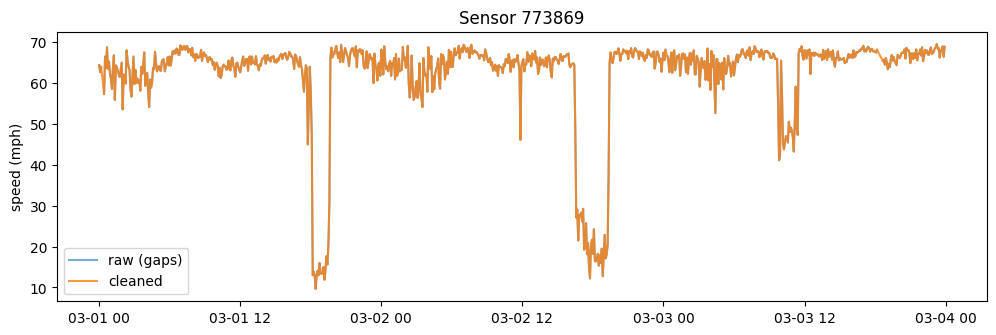

In [8]:
s = 0
sl = slice(0, 288 * 3)                               # 288 steps = 1 day
plt.figure(figsize=(12, 3.5))
plt.plot(raw_copy.index[sl], raw_copy.iloc[sl, s], label="raw (gaps)", alpha=0.6)
plt.plot(df.index[sl], df.iloc[sl, s], label="cleaned", alpha=0.8)
plt.ylabel("speed (mph)"); plt.legend(); plt.title(f"Sensor {df.columns[s]}")
plt.show()

In [10]:
T_IN      = 12        # input steps  (12 x 5 min = 1 hour history)
T_OUT     = 12        # output steps (predict next 1 hour)
TRAIN_RAT = 0.7
VAL_RAT   = 0.1       # test = remaining 0.2
USE_DOW   = False     # add day-of-week feature too?

In [11]:
data = df.values.astype("float32")                   # (T, N)
T, N = data.shape

n_train = int(T * TRAIN_RAT)
n_val   = int(T * VAL_RAT)

train_raw = data[:n_train]
val_raw   = data[n_train:n_train + n_val]
test_raw  = data[n_train + n_val:]
print("train / val / test time steps:", len(train_raw), len(val_raw), len(test_raw))

train / val / test time steps: 23990 3427 6855


In [12]:
mean, std = float(train_raw.mean()), float(train_raw.std())
print(f"train mean={mean:.3f}, std={std:.3f}")

def scale(x):   return (x - mean) / std
def inverse(x): return x * std + mean

train mean=58.452, std=12.855


In [13]:
def build_features(raw, index):
    """returns (T, N, F) with channel 0 = scaled speed"""
    speed = scale(raw)[..., None]                                         # (T, N, 1)
    feats = [speed]
    tod = ((index.hour * 60 + index.minute) / (24 * 60)).values.astype("float32")
    feats.append(np.broadcast_to(tod[:, None, None], speed.shape))
    if USE_DOW:
        dow = (index.dayofweek.values / 6).astype("float32")
        feats.append(np.broadcast_to(dow[:, None, None], speed.shape))
    return np.concatenate(feats, axis=-1).astype("float32")

def make_windows(feats, t_in, t_out):
    """X: (samples, t_in, N, F)   Y: (samples, t_out, N)  -> speed only"""
    starts = np.arange(t_in, feats.shape[0] - t_out + 1)
    X = np.stack([feats[i - t_in:i] for i in starts])
    Y = np.stack([feats[i:i + t_out, :, 0] for i in starts])
    return X.astype("float32"), Y.astype("float32")

idx_train = df.index[:n_train]
idx_val   = df.index[n_train:n_train + n_val]
idx_test  = df.index[n_train + n_val:]

X_train, y_train = make_windows(build_features(train_raw, idx_train), T_IN, T_OUT)
X_val,   y_val   = make_windows(build_features(val_raw,   idx_val),   T_IN, T_OUT)
X_test,  y_test  = make_windows(build_features(test_raw,  idx_test),  T_IN, T_OUT)

for name, a in [("X_train", X_train), ("y_train", y_train), ("X_val", X_val),
                ("y_val", y_val), ("X_test", X_test), ("y_test", y_test)]:
    print(f"{name:8s}", a.shape)

X_train  (23967, 12, 207, 2)
y_train  (23967, 12, 207)
X_val    (3404, 12, 207, 2)
y_val    (3404, 12, 207)
X_test   (6832, 12, 207, 2)
y_test   (6832, 12, 207)


In [14]:
def to_gru_input(X):
    s, t, n, f = X.shape
    return X.reshape(s, t, n * f)

Xtr_gru, Xva_gru, Xte_gru = map(to_gru_input, (X_train, X_val, X_test))
print("GRU input shapes:", Xtr_gru.shape, Xva_gru.shape, Xte_gru.shape)
print("GRU target shapes:", y_train.shape, y_val.shape, y_test.shape)

GRU input shapes: (23967, 12, 414) (3404, 12, 414) (6832, 12, 414)
GRU target shapes: (23967, 12, 207) (3404, 12, 207) (6832, 12, 207)


In [16]:
np.savez_compressed("metr_la_processed.npz",
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test,
                    mean=mean, std=std,
                    sensor_ids=np.array(df.columns))
files.download("metr_la_processed.npz")             # optional: keep a copy
print("saved")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved


GRU


In [17]:
import os, time, copy
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from google.colab import files

torch.manual_seed(42); np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [18]:
if not os.path.exists("metr_la_processed.npz"):
    files.upload()                                   # choose metr_la_processed.npz

d = np.load("metr_la_processed.npz", allow_pickle=True)
X_train, y_train = d["X_train"], d["y_train"]
X_val,   y_val   = d["X_val"],   d["y_val"]
X_test,  y_test  = d["X_test"],  d["y_test"]
mean, std = float(d["mean"]), float(d["std"])

def to_gru(X):                                       # (S, T, N, F) -> (S, T, N*F)
    return X.reshape(X.shape[0], X.shape[1], -1)

Xtr, Xva, Xte = map(to_gru, (X_train, X_val, X_test))
N_SENSORS = y_train.shape[2]
T_OUT     = y_train.shape[1]
F         = X_train.shape[3]
print("Input:", Xtr.shape, "| Target:", y_train.shape, "| sensors:", N_SENSORS, "| features:", F)

Input: (23967, 12, 414) | Target: (23967, 12, 207) | sensors: 207 | features: 2


In [19]:
BATCH = 64
def loader(X, y, shuffle):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, drop_last=False)

train_dl = loader(Xtr, y_train, True)
val_dl   = loader(Xva, y_val,   False)
test_dl  = loader(Xte, y_test,  False)

In [23]:
class GRUForecaster(nn.Module):
    def __init__(self, in_dim, n_sensors, t_out, hidden=128, layers=2, dropout=0.2):
        super().__init__()
        self.n_sensors, self.t_out = n_sensors, t_out
        self.gru  = nn.GRU(in_dim, hidden, num_layers=layers,
                           batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, t_out * n_sensors))
    def forward(self, x):                            # x: (B, T_in, N*F)
        out, _ = self.gru(x)
        h = out[:, -1]                               # last time step
        return self.head(h).view(-1, self.t_out, self.n_sensors)

model = GRUForecaster(Xtr.shape[2], N_SENSORS, T_OUT).to(device)
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

GRUForecaster(
  (gru): GRU(414, 128, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=2484, bias=True)
  )
)
Parameters: 644916


In [25]:
EPOCHS, PATIENCE, LR = 60, 8, 1e-3
criterion = nn.L1Loss()
optim = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, factor=0.5, patience=3)

def run_epoch(dl, train):
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            loss = criterion(pred, yb)
            if train:
                optim.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optim.step()
            total += loss.item() * len(xb); n += len(xb)
    return total / n

best_val, best_state, wait = float("inf"), None, 0
hist = {"train": [], "val": []}
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    tr, va = run_epoch(train_dl, True), run_epoch(val_dl, False)
    sched.step(va)
    hist["train"].append(tr); hist["val"].append(va)
    print(f"Epoch {ep:02d} | train {tr:.4f} | val {va:.4f} | lr {optim.param_groups[0]['lr']:.1e} | {time.time()-t0:.0f}s")
    if va < best_val:
        best_val, best_state, wait = va, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping."); break

model.load_state_dict(best_state)
torch.save(best_state, "gru_metrla_best.pt")
print("Best val loss (scaled):", round(best_val, 4))

Epoch 01 | train 0.2224 | val 0.2584 | lr 1.0e-03 | 29s
Epoch 02 | train 0.2215 | val 0.2590 | lr 1.0e-03 | 20s
Epoch 03 | train 0.2203 | val 0.2581 | lr 1.0e-03 | 21s
Epoch 04 | train 0.2193 | val 0.2573 | lr 1.0e-03 | 20s
Epoch 05 | train 0.2183 | val 0.2580 | lr 1.0e-03 | 22s
Epoch 06 | train 0.2176 | val 0.2584 | lr 1.0e-03 | 20s
Epoch 07 | train 0.2168 | val 0.2578 | lr 1.0e-03 | 21s
Epoch 08 | train 0.2162 | val 0.2593 | lr 5.0e-04 | 20s
Epoch 09 | train 0.2126 | val 0.2578 | lr 5.0e-04 | 21s
Epoch 10 | train 0.2121 | val 0.2575 | lr 5.0e-04 | 20s
Epoch 11 | train 0.2117 | val 0.2575 | lr 5.0e-04 | 21s
Epoch 12 | train 0.2114 | val 0.2585 | lr 2.5e-04 | 21s
Early stopping.
Best val loss (scaled): 0.2573


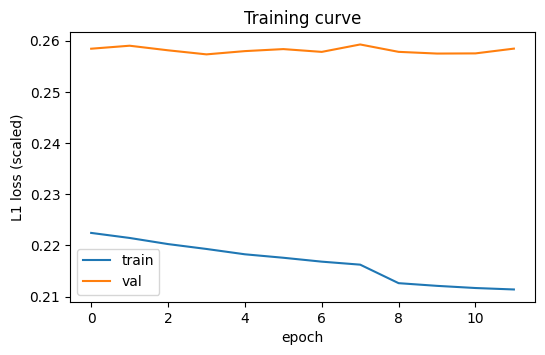

In [26]:
plt.figure(figsize=(6,3.5))
plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.xlabel("epoch"); plt.ylabel("L1 loss (scaled)"); plt.legend(); plt.title("Training curve")
plt.show()

In [27]:
@torch.no_grad()
def predict(dl):
    model.eval()
    out = [model(xb.to(device)).cpu().numpy() for xb, _ in dl]
    return np.concatenate(out)

pred_test = predict(test_dl) * std + mean            # (S, 12, N) in mph
true_test = y_test * std + mean
print(pred_test.shape, true_test.shape)

(6832, 12, 207) (6832, 12, 207)


In [28]:
import pandas as pd
mask_test = np.ones_like(true_test, dtype=bool)
try:
    if not os.path.exists("metr-la.csv"):
        files.upload()                               # choose metr-la.csv
    raw = pd.read_csv("metr-la.csv")
    first = raw.columns[0]
    if raw[first].dtype == object or str(first).lower().startswith(("unnamed", "index")):
        raw = raw.drop(columns=first)
    valid = (raw.apply(pd.to_numeric, errors="coerce").values != 0)   # True = real reading
    Tn = valid.shape[0]
    n_train = int(Tn * 0.7); n_val = int(Tn * 0.1)
    v_test = valid[n_train + n_val:]
    starts = np.arange(12, v_test.shape[0] - T_OUT + 1)               # T_IN = 12
    mask_test = np.stack([v_test[i:i + T_OUT] for i in starts])
    assert mask_test.shape == true_test.shape, (mask_test.shape, true_test.shape)
    print(f"Mask built. Valid test targets: {mask_test.mean()*100:.1f}%")
except Exception as e:
    print("Mask not built, using all values. Reason:", e)
    mask_test = np.ones_like(true_test, dtype=bool)

Mask built. Valid test targets: 87.9%


In [29]:
def metrics(pred, true, mask):
    m = mask & (true > 0)
    err = (pred - true)[m]
    mae  = np.abs(err).mean()
    rmse = np.sqrt((err ** 2).mean())
    mape = (np.abs(err) / true[m]).mean() * 100
    return mae, rmse, mape

# baseline: repeat the last observed speed (channel 0 of the last input step)
last_speed = Xte[:, -1, 0::F] * std + mean           # (S, N)
base_test  = np.repeat(last_speed[:, None, :], T_OUT, axis=1)

rows = []
for name, P in [("Last value", base_test), ("GRU", pred_test)]:
    for label, h in [("15 min", 2), ("30 min", 5), ("60 min", 11)]:
        mae, rmse, mape = metrics(P[:, h], true_test[:, h], mask_test[:, h])
        rows.append((name, label, mae, rmse, mape))
    mae, rmse, mape = metrics(P, true_test, mask_test)
    rows.append((name, "average", mae, rmse, mape))

import pandas as pd
res = pd.DataFrame(rows, columns=["Model", "Horizon", "MAE", "RMSE", "MAPE %"]).round(3)
res

,Model,Horizon,MAE,RMSE,MAPE %
0,Last value,15 min,3.460,6.313,8.474
1,Last value,30 min,4.149,7.920,10.674
2,Last value,60 min,5.296,10.194,14.282
3,Last value,average,4.184,8.063,10.779
4,GRU,15 min,3.405,6.544,9.700
5,GRU,30 min,3.513,6.854,10.126
6,GRU,60 min,3.789,7.440,11.175
7,GRU,average,3.550,6.912,10.260


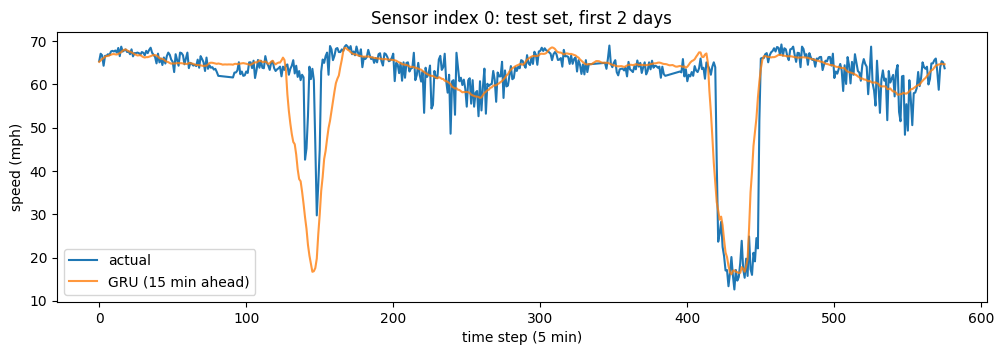

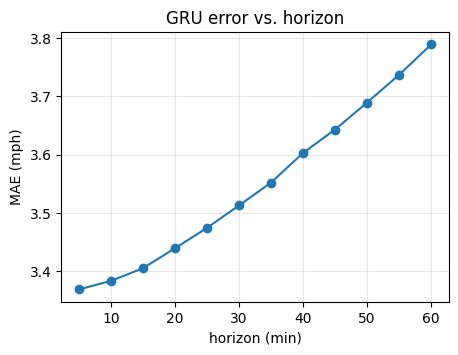

In [30]:
S, h, sensor = 288 * 2, 2, 0                         # 2 days, 15-min ahead, sensor 0
plt.figure(figsize=(12, 3.5))
plt.plot(true_test[:S, h, sensor], label="actual")
plt.plot(pred_test[:S, h, sensor], label="GRU (15 min ahead)", alpha=0.8)
plt.xlabel("time step (5 min)"); plt.ylabel("speed (mph)"); plt.legend()
plt.title(f"Sensor index {sensor}: test set, first 2 days")
plt.show()

mae_h = [metrics(pred_test[:, k], true_test[:, k], mask_test[:, k])[0] for k in range(T_OUT)]
plt.figure(figsize=(5, 3.5))
plt.plot(range(5, 5 * T_OUT + 1, 5), mae_h, marker="o")
plt.xlabel("horizon (min)"); plt.ylabel("MAE (mph)"); plt.title("GRU error vs. horizon")
plt.grid(alpha=0.3); plt.show()

In [31]:
res.to_csv("gru_metrla_results.csv", index=False)
files.download("gru_metrla_best.pt")                 # optional: save trained weights
files.download("gru_metrla_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>